In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.15.0+cpu
Device : cpu


In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

100.0%
100.0%
100.0%
100.0%


Train : 60000
Test  : 10000


torch.Size([128, 1, 28, 28]) torch.Size([128])


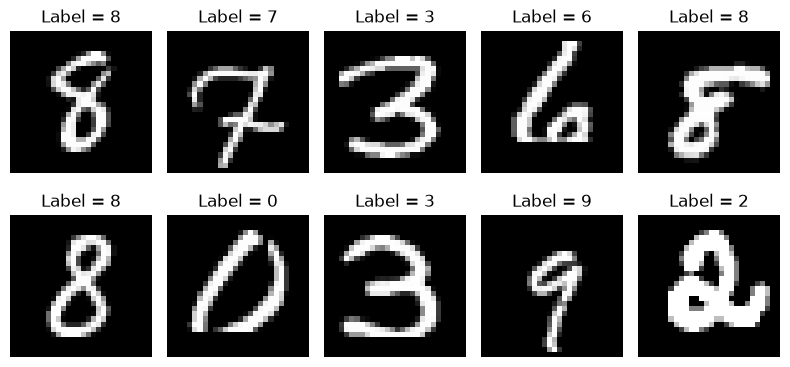

In [3]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),          # [1,28,28] -> 784
            nn.Linear(784, 128),   # couche cachée
            nn.ReLU(),
            nn.Linear(128, 10)     # 10 classes (logits)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [7]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} - Loss = {total_loss/len(loader):.4f}")

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4171
Epoch 2/3 - Loss = 0.1896
Epoch 3/3 - Loss = 0.1362


In [8]:
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.37%


In [9]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier_torcheval(model, loader):
    model.eval()
    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        metric.update(model(x), y)

    return metric.compute().item()

print(f"Accuracy (torcheval) = {100 * evaluate_classifier_torcheval(classifier, test_loader):.2f}%")

c:\Users\bouho\Desktop\tp_generatif\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy (torcheval) = 96.37%
